# Immuno Compass · Notebook 06: Model 3, XGBoost (Day 6)

**Goal:** train a flexible machine-learning model, tune it lightly (honestly, inside the training folds only), and
compare it with the naive baseline and the GLM on **unseen drugs**.

**Finish line:** grouped-CV scores saved in `results/`, a first model-comparison chart, feature importance, and a
final model saved in `models/` for the dashboard.

> 🧒 *Simple version:* XGBoost plays **20 Questions** many times. Each small "question tree" asks things like
> *"Is it bacterial? Is the dose high?"* and makes a small correction to the guess. Hundreds of small trees, each fixing the
> mistakes of the previous ones, add up to the final prediction. That's called **gradient boosting**.

### How it differs from the GLM
| | GLM | XGBoost |
|---|---|---|
| Shape of effects | straight lines on the logit scale | any shape (steps, curves) |
| Interactions ("dose matters only for SC drugs") | only if we add them by hand | found automatically |
| Interpretability | odds ratios | needs SHAP (Day 14) |
| Risk | under-fitting | over-fitting → we limit depth and learning rate |

**Objective:** `reg:logistic` = cross-entropy on the ADA frequency y/n. Weighted by n, this is exactly the Binomial
log-likelihood, so XGBoost optimises the same thing as the GLM, just with trees instead of a straight line.

In [1]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # The repo is private, so Colab needs a GitHub token once per session.
    # Make one at github.com/settings/tokens (fine-grained, read access to immuno-compass).
    from getpass import getpass
    token = getpass("GitHub token: ")
    !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
    del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels xgboost

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

repo root: immuno-compass


In [2]:
import warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import GroupKFold
np.random.seed(42)
warnings.filterwarnings("ignore", message="Found unknown categories")

df = im.load_cohorts(ROOT).join(im.load_folds(ROOT)[["fold_grouped", "fold_random"]])
print(df.shape, "| drugs:", df[im.DRUG].nunique())

BLUE, ORANGE, AQUA, GRAY, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "savefig.dpi": 200, "savefig.bbox": "tight", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID})

(1754, 40) | drugs: 137


## 1 · First, the settings from the project plan (untuned)

400 trees, learning rate 0.05, depth 4, 80 % row and column sampling, each cohort weighted by n.

In [3]:
def xgb_fixed(max_depth, weight):
    def fn(train, test):
        pre, model = im.fit_xgb(train, max_depth=max_depth, weight=weight)
        return im.predict_xgb(pre, model, test)
    return fn

for split in ["fold_grouped", "fold_random"]:
    pf, oof = im.cross_validate(df, split, xgb_fixed(4, "n"))
    if split == "fold_grouped":
        im.save_results("xgb_default", pf, oof, df, ROOT)   # settings fixed in the plan BEFORE seeing data → an honest score
    print(f"{split:13s}", {k: round(v, 4) for k, v in pf.drop(columns="fold").mean().items()})

fold_grouped  {'wMAE': 0.1307, 'wRMSE': 0.1812, 'loglik': -19.1863}


fold_random   {'wMAE': 0.0697, 'wRMSE': 0.1128, 'loglik': -7.3778}


As with the GLM, the **random split looks much better** (the trees recognise drugs they've already seen). From here on
we only use the honest grouped split.

## 2 · Light, honest tuning (nested CV)

We try **4 settings** and let an *inner* grouped CV (inside each training fold) pick one:

| Setting | Options | Why |
|---|---|---|
| `max_depth` | 4 or 2 | deeper trees = more interactions, but more over-fitting |
| cohort weight | n or √n | with overdispersion, a 10,000-patient trial is **not** 100× more informative than a 100-patient one about *other* drugs; √n lets big cohorts count less |

The test fold is **never** used to choose. Inner selection is by held-out Binomial log-likelihood.

In [4]:
def xgb_tuned(inner_splits=4):
    picked = []
    def fn(train, test):
        best, best_ll = None, -np.inf
        for cfg in im.XGB_GRID:
            lls = []
            for tr_idx, va_idx in GroupKFold(n_splits=inner_splits).split(train, groups=train[im.DRUG]):
                tr, va = train.iloc[tr_idx], train.iloc[va_idx]
                pre, model = im.fit_xgb(tr, **cfg)
                lls.append(im.mean_loglik(va["y"], va["n"], im.predict_xgb(pre, model, va)))
            if np.mean(lls) > best_ll:
                best, best_ll = cfg, np.mean(lls)
        picked.append(best)
        pre, model = im.fit_xgb(train, **best)
        return im.predict_xgb(pre, model, test)
    return fn, picked

fn, picked = xgb_tuned()
pf_xgb, oof_xgb = im.cross_validate(df, "fold_grouped", fn)
im.save_results("xgb", pf_xgb, oof_xgb, df, ROOT)
for k, cfg in enumerate(picked):
    print(f"outer fold {k}: picked {cfg}")
print("\nXGBoost (tuned), grouped CV:", {k: round(v, 4) for k, v in pf_xgb.drop(columns="fold").mean().items()})

outer fold 0: picked {'max_depth': 4, 'weight': 'sqrt_n'}
outer fold 1: picked {'max_depth': 4, 'weight': 'sqrt_n'}
outer fold 2: picked {'max_depth': 2, 'weight': 'sqrt_n'}
outer fold 3: picked {'max_depth': 4, 'weight': 'sqrt_n'}
outer fold 4: picked {'max_depth': 2, 'weight': 'sqrt_n'}

XGBoost (tuned), grouped CV: {'wMAE': 0.1395, 'wRMSE': 0.1898, 'loglik': -19.7777}


### 2b · What if we had picked the setting by peeking? (don't do this)

Below are all 4 settings scored directly on the test folds. Picking the best row **after** seeing these numbers would
be optimistic, because we would be choosing with the test data. It shows how noisy the choice is.

In [5]:
hindsight = []
for cfg in im.XGB_GRID:
    pf, _ = im.cross_validate(df, "fold_grouped", xgb_fixed(cfg["max_depth"], cfg["weight"]))
    hindsight.append({**cfg, **pf.drop(columns="fold").mean().to_dict(), "per_fold_wMAE": pf["wMAE"].round(3).tolist()})
display(pd.DataFrame(hindsight).style.format({"wMAE": "{:.4f}", "wRMSE": "{:.4f}", "loglik": "{:.2f}"}).hide(axis="index"))

max_depth,weight,wMAE,wRMSE,loglik,per_fold_wMAE
4,n,0.1307,0.1812,-19.19,"[0.097, 0.12, 0.151, 0.099, 0.186]"
4,sqrt_n,0.1251,0.1727,-17.35,"[0.094, 0.124, 0.13, 0.097, 0.182]"
2,n,0.1479,0.1988,-21.20,"[0.107, 0.122, 0.205, 0.106, 0.199]"
2,sqrt_n,0.1413,0.1894,-19.34,"[0.095, 0.12, 0.19, 0.108, 0.193]"


**Reading this:** depth-4 trees with √n weights are best on 4 of 5 folds, but the inner CV (which only sees ~110 training
drugs) sometimes preferred depth 2, and on folds 2 and 4 that hurt. **Choosing a setting is itself noisy when there are
few drugs.** We report the honest numbers: the plan's pre-set setting and the nested-CV tuned one. The hindsight best is
only a ceiling.

## 3 · Scoreboard so far (grouped CV, unseen drugs)

All models use the same 5 folds and the same scores. `results/` holds every model's per-fold numbers.

In [6]:
NAMES = {"naive": "Naive baseline", "glm_plain": "GLM (plain)", "glm_l2": "GLM + L2 (tuned)",
         "glm_l1": "GLM + L1 (tuned)", "xgb_default": "XGBoost (plan settings)", "xgb": "XGBoost (tuned)"}
cv = pd.concat([pd.read_csv(ROOT / "results" / f"cv_{k}.csv") for k in NAMES])
board = (cv.groupby("model")[["wMAE", "wRMSE", "loglik"]].agg(["mean", "std"]).reindex(list(NAMES)))
board.index = [NAMES[k] for k in board.index]
display(board.style.format("{:.3f}"))

# Paired comparison: in how many of the 5 folds does each XGBoost beat the naive baseline?
base = cv[cv.model == "naive"].set_index("fold")
for key in ["xgb_default", "xgb"]:
    xgb = cv[cv.model == key].set_index("fold")
    print(f"\n{NAMES[key]} vs naive baseline:")
    for m, better in [("wMAE", "lower"), ("wRMSE", "lower"), ("loglik", "higher")]:
        diff = xgb[m] - base[m]
        wins = (diff < 0).sum() if better == "lower" else (diff > 0).sum()
        print(f"  {m:6s}: difference {diff.mean():+.4f} (fold SD {diff.std():.4f}); better in {wins}/5 folds")


XGBoost (plan settings) vs naive baseline:
  wMAE  : difference -0.0063 (fold SD 0.0210); better in 3/5 folds
  wRMSE : difference -0.0078 (fold SD 0.0255); better in 3/5 folds
  loglik: difference -1.1293 (fold SD 4.8350); better in 2/5 folds

XGBoost (tuned) vs naive baseline:
  wMAE  : difference +0.0025 (fold SD 0.0367); better in 3/5 folds
  wRMSE : difference +0.0009 (fold SD 0.0447); better in 3/5 folds
  loglik: difference -1.7208 (fold SD 7.2823); better in 3/5 folds


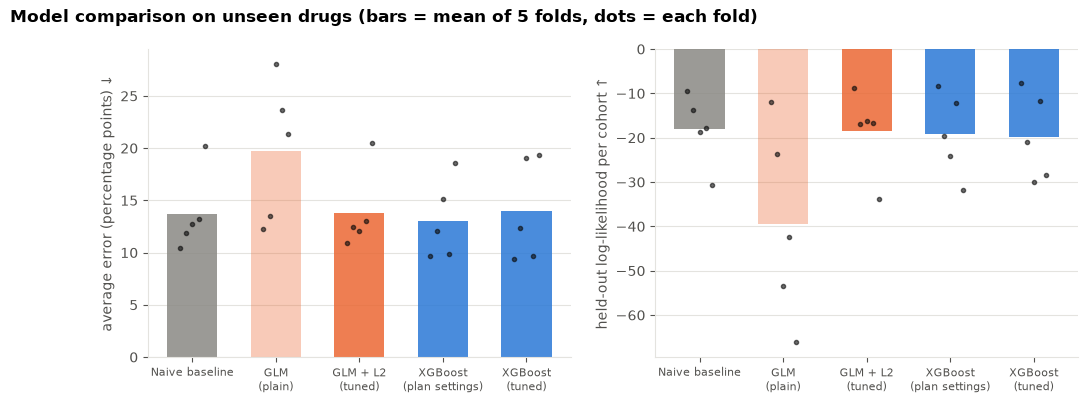

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ["naive", "glm_plain", "glm_l2", "xgb_default", "xgb"]
colors = {"naive": GRAY, "glm_plain": ORANGE, "glm_l2": ORANGE, "xgb_default": BLUE, "xgb": BLUE}
for ax, metric, label in [(axes[0], "wMAE", "average error (percentage points) ↓"),
                          (axes[1], "loglik", "held-out log-likelihood per cohort ↑")]:
    scale = 100 if metric == "wMAE" else 1
    for i, k in enumerate(order):
        v = cv[cv.model == k][metric] * scale
        ax.bar(i, v.mean(), 0.6, color=colors[k], alpha=0.35 if k == "glm_plain" else 0.85)
        ax.plot(np.full(len(v), i) + np.linspace(-0.15, 0.15, len(v)), v, "o", color="#0b0b0b", ms=3, alpha=0.6)
    ax.set_xticks(range(len(order)), [NAMES[k].replace(" (", "\n(") for k in order], fontsize=8)
    ax.set_ylabel(label); ax.grid(axis="x", visible=False)
    if metric == "wMAE": ax.set_ylim(0, None)
fig.suptitle("Model comparison on unseen drugs (bars = mean of 5 folds, dots = each fold)", x=0.01, ha="left", fontweight="bold")
fig.savefig(ROOT / "figures" / "model_comparison_day6.png"); plt.show()

## 4 · Which clues does XGBoost use? (first look; SHAP comes on Day 14)

We refit the tuned setting on **all** cohorts and add up "gain" (how much each clue improved the fit) over its one-hot
columns. ⚠️ Gain shows what the model *uses*, not the direction of the effect, and it can favour clues with many levels.

final setting (picked most often across outer folds): {'max_depth': 4, 'weight': 'sqrt_n'}


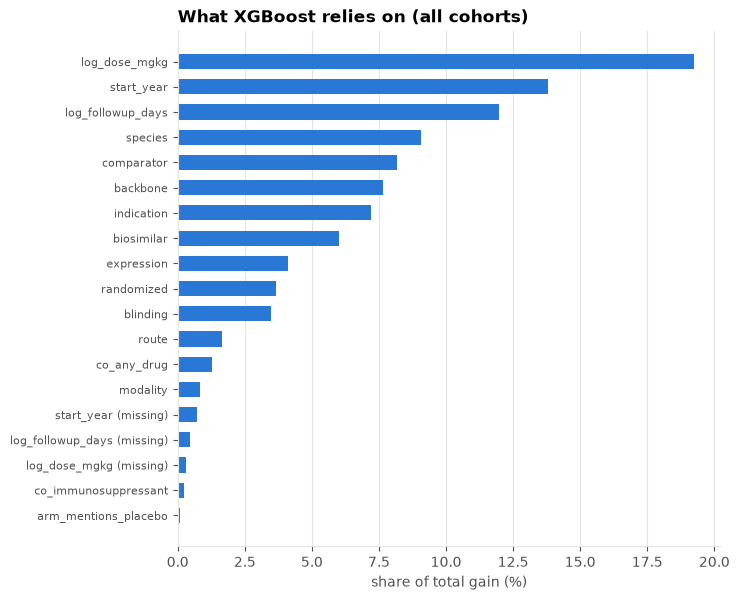

,share
log_dose_mgkg,19.3%
start_year,13.8%
log_followup_days,12.0%
species,9.1%
comparator,8.2%
backbone,7.7%
indication,7.2%
biosimilar,6.0%
expression,4.1%
randomized,3.7%


In [8]:
from collections import Counter
final_cfg = Counter(json.dumps(c, sort_keys=True) for c in picked).most_common(1)[0][0]
final_cfg = json.loads(final_cfg)
print("final setting (picked most often across outer folds):", final_cfg)
pre_final, xgb_final = im.fit_xgb(df, **final_cfg)

gain = xgb_final.get_booster().get_score(importance_type="total_gain")
cols = pre_final.get_feature_names_out()
per_col = pd.Series({cols[int(k[1:])]: v for k, v in gain.items()})       # 'f12' -> column name

def base_feature(col):
    if col.startswith("missingindicator_"):
        return col.replace("missingindicator_", "") + " (missing)"
    return next((c for c in im.CAT_FEATURES if col.startswith(c + "_")), col)

imp = per_col.groupby(base_feature).sum().sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(7, 0.3 * len(imp) + 1))
ax.barh(range(len(imp)), imp.values * 100, color=BLUE, height=0.6)
ax.set_yticks(range(len(imp)), imp.index, fontsize=8)
ax.set_xlabel("share of total gain (%)"); ax.set_title("What XGBoost relies on (all cohorts)")
ax.grid(axis="y", visible=False)
fig.savefig(ROOT / "figures" / "xgb_importance_gain.png"); plt.show()
display(imp.sort_values(ascending=False).rename("share").to_frame().style.format("{:.1%}"))

## 5 · Save the final model for the dashboard

The dashboard (Day 16) will **load** this file and never retrain, so it uses exactly this preprocessing and model.

In [9]:
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump({"preprocessor": pre_final, "model": xgb_final, "config": final_cfg,
             "features": im.ALL_FEATURES}, ROOT / "models" / "xgb_model.joblib")
check = joblib.load(ROOT / "models" / "xgb_model.joblib")
assert np.allclose(im.predict_xgb(check["preprocessor"], check["model"], df.head(20)),
                   im.predict_xgb(pre_final, xgb_final, df.head(20)))
print("saved models/xgb_model.joblib and reloaded it ✔")

saved models/xgb_model.joblib and reloaded it ✔


## 6 · Day 6 findings (write-up)

**Scoreboard on unseen drugs (grouped 5-fold CV, mean ± fold SD):**

| model | wMAE ↓ | wRMSE ↓ | loglik ↑ |
|---|---|---|---|
| Naive baseline | 0.137 ± 0.038 | 0.189 ± 0.060 | −18.1 ± 8.0 |
| GLM (plain) | 0.198 ± 0.068 | 0.276 ± 0.098 | −39.5 ± 22.0 |
| GLM + L2 (tuned) | 0.138 ± 0.038 | 0.185 ± 0.063 | −18.5 ± 9.3 |
| **XGBoost (plan settings)** | **0.131 ± 0.038** | **0.181 ± 0.054** | −19.2 ± 9.4 |
| XGBoost (tuned) | 0.140 ± 0.049 | 0.190 ± 0.066 | −19.8 ± 9.9 |

1. **XGBoost with the plan's pre-set settings is the best so far on average error**, by about 0.6 percentage points (wMAE) and 0.8 points (wRMSE) over the naive baseline. It wins in 3 of 5 folds, and the gain is **much smaller than the fold-to-fold spread** (SD ≈ 2 points). It is **not** better on log-likelihood (−19.2 vs −18.1). Its predicted probabilities are sometimes over-confident for individual cohorts, which is the overdispersion problem again.
2. **Light tuning did not help.** Inner CV picked √n weighting every time (sensible, given overdispersion) but chose depth 2 in two folds where depth 2 does badly. With ~110 training drugs, choosing settings is itself noisy. The "best in hindsight" setting (depth 4, √n) would score wMAE 0.125, but that number is **optimistic** because it was picked using the test folds, so we don't claim it.
3. **Leakage again:** under a random split the same XGBoost scores wMAE 0.070, half the honest error.
4. **What XGBoost relies on (gain):** dose (19 %), trial start year (14 %) and follow-up length (12 %) lead, then species/origin (9 %), comparator (8 %), backbone (8 %) and disease area (7 %). This broadly agrees with the GLM (year, dose, follow-up, origin, backbone, comparator). Continuous clues can rank high in gain partly because trees can split them many times; SHAP on Day 14 will show direction and size.

**Honest summary after Week 1's models:** both model families capture *some* real signal (assay era, dose, follow-up, drug origin), but predicting ADA for a **brand-new drug** from these clues improves only modestly on "guess the average", because most variation is drug-specific. This is a legitimate finding and sets up the two remaining questions: does a model that handles **overdispersion** (Bayesian Beta-Binomial) give better-calibrated probabilities, and do **sequence features** add drug-specific information?